Method	What we want to test
0-hop	Can the matching node alone provide the answer?
1-hop	Does retrieving immediate neighbors improve completeness?
2-hop	Can we find answers distributed across connected nodes?
Relationship-aware	Can we retrieve the relevant facts without unnecessary nodes?
Multi-entity	Can we combine or compare facts from separate nodes?

In [1]:
from pathlib import Path
from dotenv import load_dotenv
from neo4j import GraphDatabase
import pandas as pd
import os
import time

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

load_dotenv(project_root / ".env")

DATABASE = os.getenv("NEO4J_DATABASE", "neo4j")

driver = GraphDatabase.driver(
    os.getenv("NEO4J_URI"),
    auth=(
        os.getenv("NEO4J_USER"),
        os.getenv("NEO4J_PASSWORD")
    )
)

driver.verify_connectivity()
print("Connected to local Neo4j!")

Connected to local Neo4j!


Define the first test question
Question:
ඇල්ල පිහිටා තිබෙන දිස්ත්‍රික්කය අයත් වන පළාත කුමක්ද?
Expected answer: ඌව පළාත

In [2]:
test_question = {
    "id": "Q001",
    "question_si": "ඇල්ල පිහිටා තිබෙන දිස්ත්‍රික්කය අයත් වන පළාත කුමක්ද?",
    "entity_id": "D001",
    "expected_answer": "ඌව පළාත",
    "required_facts": [
        ("D001", "LOCATED_IN", "DI001"),
        ("DI001", "PART_OF", "P001")
    ]
}

print("Question:", test_question["question_si"])
print("Expected answer:", test_question["expected_answer"])

Question: ඇල්ල පිහිටා තිබෙන දිස්ත්‍රික්කය අයත් වන පළාත කුමක්ද?
Expected answer: ඌව පළාත


Implement three retrieval methods
1.Single-node retrieval (0-hop)

This retrieves only Ella's properties.

In [3]:
def retrieve_0hop(entity_id):
    records, _, _ = driver.execute_query(
        """
        MATCH (n:Entity {id: $entity_id})
        RETURN properties(n) AS node
        """,
        entity_id=entity_id,
        database_=DATABASE
    )

    return [dict(record["node"]) for record in records]


result_0hop = retrieve_0hop("D001")

print("0-hop result:")
for item in result_0hop:
    print(item)

0-hop result:
{'elevation_m': 1041, 'climate_si': 'සාමාන්\u200dයයෙන් සිසිල් කඳුකර දේශගුණය', 'name_si': 'ඇල්ල', 'source_document': 'ella.txt', 'id': 'D001', 'source_section': '1, 2'}


One-hop retrieval

This retrieves all direct neighbors of Ella.

It should include Badulla District, but not necessarily Uva Province, because that requires following a second relationship.

In [4]:
def retrieve_1hop(entity_id):
    records, _, _ = driver.execute_query(
        """
        MATCH (n:Entity {id: $entity_id})-[r]-(neighbor:Entity)
        RETURN
            n.id AS start_id,
            n.name_si AS start_name,
            type(r) AS relationship,
            startNode(r).id AS source_id,
            endNode(r).id AS target_id,
            neighbor.id AS neighbor_id,
            neighbor.name_si AS neighbor_name
        """,
        entity_id=entity_id,
        database_=DATABASE
    )

    return [dict(record) for record in records]


result_1hop = retrieve_1hop("D001")

display(pd.DataFrame(result_1hop))

,start_id,start_name,relationship,source_id,target_id,neighbor_id,neighbor_name
0,D001,ඇල්ල,LOCATED_IN,D001,DI001,DI001,බදුල්ල
1,D001,ඇල්ල,HAS_ATTRACTION,D001,A001,A001,පුංචි ශ්‍රී පාදය
2,D001,ඇල්ල,HAS_ATTRACTION,D001,A002,A002,ඇල්ල රොක්
3,D001,ඇල්ල,HAS_ATTRACTION,D001,A003,A003,ආරුක්කු නවයේ පාලම
4,D001,ඇල්ල,HAS_ATTRACTION,D001,A004,A004,රාවණා ඇල්ල
5,D001,ඇල්ල,HAS_ATTRACTION,D001,A005,A005,රාවණා ගුහාව
6,D001,ඇල්ල,HAS_ATTRACTION,D001,A006,A006,දෝව රජමහා විහාරය
7,D001,ඇල්ල,HAS_ATTRACTION,D001,A007,A007,දියලුම දිය ඇල්ල
8,D001,ඇල්ල,HAS_ATTRACTION,D001,A008,A008,නිල්දිය පොකුණ
9,D001,ඇල්ල,HAS_ACTIVITY,D001,AC001,AC001,කඳු නැගීම


Two-hop retrieval

This retrieves paths up to two relationships away, with a limit of 100 paths to control the amount of data returned.

In [5]:
def retrieve_2hop(entity_id):
    records, _, _ = driver.execute_query(
        """
        MATCH p = (n:Entity {id: $entity_id})-[*1..2]-(m:Entity)
        WITH p
        LIMIT 100
        RETURN
            [node IN nodes(p) |
                {id: node.id, name: node.name_si}
            ] AS nodes,
            [rel IN relationships(p) |
                {
                    type: type(rel),
                    source: startNode(rel).id,
                    target: endNode(rel).id
                }
            ] AS relationships
        """,
        entity_id=entity_id,
        database_=DATABASE
    )

    return [dict(record) for record in records]


result_2hop = retrieve_2hop("D001")

print("Paths returned:", len(result_2hop))

for path in result_2hop[:5]:
    print(path)

Paths returned: 30
{'nodes': [{'id': 'D001', 'name': 'ඇල්ල'}, {'id': 'DI001', 'name': 'බදුල්ල'}], 'relationships': [{'source': 'D001', 'target': 'DI001', 'type': 'LOCATED_IN'}]}
{'nodes': [{'id': 'D001', 'name': 'ඇල්ල'}, {'id': 'DI001', 'name': 'බදුල්ල'}, {'id': 'P001', 'name': 'ඌව පළාත'}], 'relationships': [{'source': 'D001', 'target': 'DI001', 'type': 'LOCATED_IN'}, {'source': 'DI001', 'target': 'P001', 'type': 'PART_OF'}]}
{'nodes': [{'id': 'D001', 'name': 'ඇල්ල'}, {'id': 'A001', 'name': 'පුංචි ශ්\u200dරී පාදය'}], 'relationships': [{'source': 'D001', 'target': 'A001', 'type': 'HAS_ATTRACTION'}]}
{'nodes': [{'id': 'D001', 'name': 'ඇල්ල'}, {'id': 'A001', 'name': 'පුංචි ශ්\u200dරී පාදය'}, {'id': 'AC001', 'name': 'කඳු නැගීම'}], 'relationships': [{'source': 'D001', 'target': 'A001', 'type': 'HAS_ATTRACTION'}, {'source': 'A001', 'target': 'AC001', 'type': 'SUPPORTS_ACTIVITY'}]}
{'nodes': [{'id': 'D001', 'name': 'ඇල්ල'}, {'id': 'A002', 'name': 'ඇල්ල රොක්'}], 'relationships': [{'source': 'D

Implement relationship-aware retrieval

Retrieve only the required relationships

In [6]:
def retrieve_province(entity_id):
    records, _, _ = driver.execute_query(
        """
        MATCH (d:Destination {id: $entity_id})
              -[:LOCATED_IN]->(district:District)
              -[:PART_OF]->(province:Province)

        RETURN
            d.name_si AS destination,
            district.name_si AS district,
            province.name_si AS province
        """,
        entity_id=entity_id,
        database_=DATABASE
    )

    return [dict(record) for record in records]


result_filtered = retrieve_province("D001")

display(pd.DataFrame(result_filtered))

,destination,district,province
0,ඇල්ල,බදුල්ල,ඌව පළාත


Understand the expected comparison
Retrieval strategy	Expected result	Sufficient evidence?
0-hop	Ella properties	Generally no
1-hop	Ella and direct neighbors	No, missing province link
2-hop	Includes Ella → Badulla → Uva	Yes, possibly with extra facts
Relationship-aware	Exact location path	Yes

automatic comparison table

In [7]:
def extract_1hop_facts(results):
    return {
        (r["source_id"], r["relationship"], r["target_id"])
        for r in results
    }


def extract_2hop_facts(results):
    facts = set()

    for path in results:
        for r in path["relationships"]:
            facts.add((
                r["source"],
                r["type"],
                r["target"]
            ))

    return facts


facts_0hop = set()

facts_1hop = extract_1hop_facts(result_1hop)

facts_2hop = extract_2hop_facts(result_2hop)

print("0-hop:", len(facts_0hop))
print("1-hop:", len(facts_1hop))
print("2-hop:", len(facts_2hop))

0-hop: 0
1-hop: 19
2-hop: 27


Extract relationship-aware evidence

In [8]:
records, _, _ = driver.execute_query(
    """
    MATCH (e:Destination {id: "D001"})
          -[r1:LOCATED_IN]->(d:District)
          -[r2:PART_OF]->(p:Province)

    RETURN
        e.id AS destination_id,
        d.id AS district_id,
        p.id AS province_id,
        type(r1) AS relation_1,
        type(r2) AS relation_2
    """,
    database_=DATABASE
)

facts_filtered = set()

for r in records:
    facts_filtered.add((
        r["destination_id"],
        r["relation_1"],
        r["district_id"]
    ))

    facts_filtered.add((
        r["district_id"],
        r["relation_2"],
        r["province_id"]
    ))

print("Relationship-aware facts:", facts_filtered)

Relationship-aware facts: {('D001', 'LOCATED_IN', 'DI001'), ('DI001', 'PART_OF', 'P001')}


Evaluate the four methods(precision and recall)

In [9]:
required = set(test_question["required_facts"])

def evaluate_retrieval(retrieved, required):
    relevant = retrieved & required

    precision = (
        len(relevant) / len(retrieved)
        if retrieved else 0.0
    )

    recall = (
        len(relevant) / len(required)
        if required else 0.0
    )

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0.0
    )

    return {
        "Retrieved facts": len(retrieved),
        "Relevant facts": len(relevant),
        "Precision": round(precision, 3),
        "Recall": round(recall, 3),
        "F1": round(f1, 3),
        "Complete evidence": required.issubset(retrieved)
    }


methods = {
    "0-hop": facts_0hop,
    "1-hop": facts_1hop,
    "2-hop": facts_2hop,
    "Relationship-aware": facts_filtered
}

results = []

for name, facts in methods.items():
    metrics = evaluate_retrieval(facts, required)
    results.append({
        "Method": name,
        **metrics
    })

evaluation_df = pd.DataFrame(results)

display(evaluation_df)

,Method,Retrieved facts,Relevant facts,Precision,Recall,F1,Complete evidence
0,0-hop,0,0,0.000,0.0,0.000,False
1,1-hop,19,1,0.053,0.5,0.095,False
2,2-hop,27,2,0.074,1.0,0.138,True
3,Relationship-aware,2,2,1.000,1.0,1.000,True


Visualize the results

In [11]:
%pip install matplotlib

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   -------- ------------------------------- 2.1/9.3 MB 11.9 MB/s eta 0:00:01
   -------------------- ------------------- 4.7/9.3 MB 12.0 MB/s eta 0:00:01
   ------------------------------ --------- 7.1/9.3 MB 12.1 MB/s eta 0:00:01
   ---------------------------------------- 9.3/9.3 MB 11.8 MB/s  0:00:00
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ------------------------------------- -- 2.4/2.5 MB 12.4 MB/s eta 0:00:01
   ---------------------------------------- 2.5/2.5 MB 11.8 MB/s  0:00:00
   ---------------------------------------- 0.0/7.3 MB ? eta -:--:--
   ------------ --------------------------- 2.4/7.3 MB 12.7 MB/s eta 0:00:01
   ---------------------------- ----------- 5.2/7.3 MB 13.2 MB/s eta 0:00:01
   ---------------------------------------- 7.3/7.3 MB 12.9 MB/s  

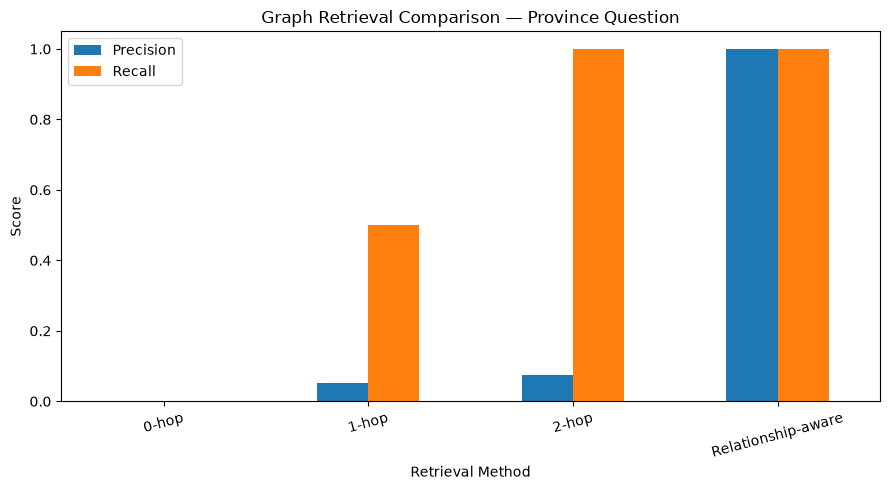

In [12]:
import matplotlib.pyplot as plt

ax = evaluation_df.set_index("Method")[
    ["Precision", "Recall"]
].plot(kind="bar", figsize=(9, 5))

ax.set_title("Graph Retrieval Comparison — Province Question")
ax.set_xlabel("Retrieval Method")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.05)

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

Save the results

In [13]:
output_dir = project_root / "results"
output_dir.mkdir(parents=True, exist_ok=True)

evaluation_df.to_csv(
    output_dir / "retrieval_comparison_q001.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Evaluation results saved successfully!")

Evaluation results saved successfully!


Multi-Question Retrieval Evaluation

goal is to determine which retrieval strategy provides sufficient evidence with the least unnecessary information before integrating SinLlama

In [14]:
test_questions = [
    {
        "id": "Q002",
        "question_si": "ඇල්ලේ නවාතැන් පහසුකම් මොනවාද?",
        "type": "one_hop",
        "entity_ids": ["D001"],
        "expected_answer": [
            "98 Acres Resort & Spa",
            "The Secret Ella",
            "Ella Jungle Resort",
            "La Ella Breeze"
        ],
        "required_facts": [
            ("D001", "HAS_ACCOMMODATION", "H001"),
            ("D001", "HAS_ACCOMMODATION", "H002"),
            ("D001", "HAS_ACCOMMODATION", "H003"),
            ("D001", "HAS_ACCOMMODATION", "H004")
        ]
    },
    {
        "id": "Q003",
        "question_si": "ඇල්ලේ කඳු නැගීමට හැකි ස්ථාන මොනවාද?",
        "type": "two_hop",
        "entity_ids": ["D001"],
        "expected_answer": ["පුංචි ශ්‍රී පාදය", "ඇල්ල රොක්"],
        "required_facts": [
            ("D001", "HAS_ATTRACTION", "A001"),
            ("A001", "SUPPORTS_ACTIVITY", "AC001"),
            ("D001", "HAS_ATTRACTION", "A002"),
            ("A002", "SUPPORTS_ACTIVITY", "AC001")
        ]
    },
    {
        "id": "Q004",
        "question_si": "රාවණා ඇල්ලේ උස කීයද?",
        "type": "node_property",
        "entity_ids": ["A004"],
        "expected_answer": "මීටර් 25ක් පමණ",
        "required_properties": [
            ("A004", "height_m", 25)
        ]
    },
    {
        "id": "Q005",
        "question_si": "රාවණා ඇල්ල සහ දියලුම ඇල්ල අතරින් උසින් වැඩි කුමක්ද?",
        "type": "multi_entity",
        "entity_ids": ["A004", "A007"],
        "expected_answer": "දියලුම දිය ඇල්ල",
        "required_properties": [
            ("A004", "height_m", 25),
            ("A007", "height_m", 220)
        ]
    },
    {
        "id": "Q006",
        "question_si": "ඇල්ලට පැමිණෙන දුම්රිය සේවා මොනවාද?",
        "type": "two_hop",
        "entity_ids": ["D001"],
        "expected_answer": [
            "පොඩි මැණිකේ",
            "උඩරට මැණිකේ",
            "දුම්රිය අංක 1007",
            "රාත්‍රී තැපැල් දුම්රිය"
        ],
        "required_facts": [
            ("D001", "HAS_RAILWAY_STATION", "RS001"),
            ("T001", "ARRIVES_AT", "RS001"),
            ("T002", "ARRIVES_AT", "RS001"),
            ("T003", "ARRIVES_AT", "RS001"),
            ("T004", "ARRIVES_AT", "RS001")
        ]
    },
    {
        "id": "Q007",
        "question_si": "පුංචි ශ්‍රී පාදයට යාමට සුදුසු කාලය කුමක්ද?",
        "type": "node_property",
        "entity_ids": ["A001"],
        "expected_answer": "උදෑසන සහ සවස් කාලය",
        "required_properties": [
            ("A001", "best_time_si", "උදෑසන සහ සවස් කාලය")
        ]
    }
]

print("Total test questions:", len(test_questions))

for question in test_questions:
    print(question["id"], "-", question["question_si"])

Total test questions: 6
Q002 - ඇල්ලේ නවාතැන් පහසුකම් මොනවාද?
Q003 - ඇල්ලේ කඳු නැගීමට හැකි ස්ථාන මොනවාද?
Q004 - රාවණා ඇල්ලේ උස කීයද?
Q005 - රාවණා ඇල්ල සහ දියලුම ඇල්ල අතරින් උසින් වැඩි කුමක්ද?
Q006 - ඇල්ලට පැමිණෙන දුම්රිය සේවා මොනවාද?
Q007 - පුංචි ශ්‍රී පාදයට යාමට සුදුසු කාලය කුමක්ද?


Build reusable retrieval functions

In [15]:
import time

def retrieve_graph(entity_ids, depth=1):
    facts = set()
    properties = set()

    for entity_id in entity_ids:

        if depth == 0:
            query = """
            MATCH (n:Entity {id: $id})
            RETURN [n] AS nodes, [] AS rels
            """
        else:
            query = f"""
            MATCH p = (n:Entity {{id: $id}})
                      -[*1..{depth}]-(m:Entity)
            RETURN nodes(p) AS nodes,
                   relationships(p) AS rels
            LIMIT 1000
            """

        records, _, _ = driver.execute_query(
            query,
            id=entity_id,
            database_=DATABASE
        )

        for record in records:
            for node in record["nodes"]:
                node_id = node.get("id")

                # Store relevant factual properties
                for key in [
                    "height_m",
                    "elevation_m",
                    "distance_from_ella_km",
                    "best_time_si",
                    "hiking_difficulty",
                    "description_si",
                    "visiting_advice_si",
                    "climate_si"
                ]:
                    if node.get(key) is not None:
                        properties.add((
                            node_id,
                            key,
                            node[key]
                        ))

            for rel in record["rels"]:
                facts.add((
                    rel.start_node["id"],
                    rel.type,
                    rel.end_node["id"]
                ))

    return {
        "relationships": facts,
        "properties": properties
    }

In [16]:
question = test_questions[3]  # Q005

print("Question:", question["question_si"])

for depth in [0, 1, 2]:
    result = retrieve_graph(
        question["entity_ids"],
        depth=depth
    )

    print(f"\n{depth}-hop")
    print("Relationships:", len(result["relationships"]))
    print("Properties:", len(result["properties"]))
    print("Retrieved properties:", result["properties"])

Question: රාවණා ඇල්ල සහ දියලුම ඇල්ල අතරින් උසින් වැඩි කුමක්ද?

0-hop
Relationships: 0
Properties: 5
Retrieved properties: {('A004', 'height_m', 25), ('A004', 'description_si', 'ඇල්ලේ සිට කිලෝමීටර් 6ක් පමණ දුරින් පිහිටි දිය ඇල්ලකි.'), ('A007', 'height_m', 220), ('A007', 'description_si', 'ඇල්ල අවට පුළුල් ප්\u200dරදේශයේ සංචාරයකදී නැරඹිය හැකි දිය ඇල්ලකි.'), ('A004', 'distance_from_ella_km', 6)}

1-hop
Relationships: 2
Properties: 7
Retrieved properties: {('A004', 'height_m', 25), ('A004', 'description_si', 'ඇල්ලේ සිට කිලෝමීටර් 6ක් පමණ දුරින් පිහිටි දිය ඇල්ලකි.'), ('D001', 'climate_si', 'සාමාන්\u200dයයෙන් සිසිල් කඳුකර දේශගුණය'), ('D001', 'elevation_m', 1041), ('A004', 'distance_from_ella_km', 6), ('A007', 'height_m', 220), ('A007', 'description_si', 'ඇල්ල අවට පුළුල් ප්\u200dරදේශයේ සංචාරයකදී නැරඹිය හැකි දිය ඇල්ලකි.')}

2-hop
Relationships: 19
Properties: 23
Retrieved properties: {('A008', 'visiting_advice_si', 'පළපුරුදු මාර්ගෝපදේශක සහාය අවශ්\u200dය විය හැකිය.'), ('A008', 'description_si', '

In [17]:
focused_queries = {
    "Q002": """
        MATCH p = (d:Destination {id: "D001"})
                  -[:HAS_ACCOMMODATION]->(h:Accommodation)
        RETURN nodes(p) AS nodes, relationships(p) AS rels
    """,

    "Q003": """
        MATCH p = (d:Destination {id: "D001"})
                  -[:HAS_ATTRACTION]->(a:Attraction)
                  -[:SUPPORTS_ACTIVITY]->(ac:Activity {id: "AC001"})
        RETURN nodes(p) AS nodes, relationships(p) AS rels
    """,

    "Q004": """
        MATCH (a:Attraction {id: "A004"})
        RETURN [a] AS nodes, [] AS rels
    """,

    "Q005": """
        MATCH (a:Attraction {id: "A004"})
        MATCH (b:Attraction {id: "A007"})
        RETURN [a, b] AS nodes, [] AS rels
    """,

    "Q006": """
        MATCH p = (d:Destination {id: "D001"})
                  -[:HAS_RAILWAY_STATION]->(s:RailwayStation)
                  <-[:ARRIVES_AT]-(t:TrainService)
        RETURN nodes(p) AS nodes, relationships(p) AS rels
    """,

    "Q007": """
        MATCH (a:Attraction {id: "A001"})
        RETURN [a] AS nodes, [] AS rels
    """
}


def retrieve_focused(question_id):
    query = focused_queries[question_id]

    records, _, _ = driver.execute_query(
        query,
        database_=DATABASE
    )

    facts = set()
    properties = set()

    for record in records:
        for node in record["nodes"]:
            node_id = node["id"]

            for key in [
                "height_m",
                "elevation_m",
                "distance_from_ella_km",
                "best_time_si",
                "hiking_difficulty",
                "description_si",
                "visiting_advice_si",
                "climate_si"
            ]:
                if node.get(key) is not None:
                    properties.add((node_id, key, node[key]))

        for rel in record["rels"]:
            facts.add((
                rel.start_node["id"],
                rel.type,
                rel.end_node["id"]
            ))

    return {
        "relationships": facts,
        "properties": properties
    }

In [18]:
def evaluate_question(result, question):

    required = set()

    for fact in question.get("required_facts", []):
        required.add(("R", *fact))

    for prop in question.get("required_properties", []):
        required.add(("P", *prop))

    retrieved = set()

    for fact in result["relationships"]:
        retrieved.add(("R", *fact))

    for prop in result["properties"]:
        retrieved.add(("P", *prop))

    relevant = retrieved & required

    precision = len(relevant) / len(retrieved) if retrieved else 0
    recall = len(relevant) / len(required) if required else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    return {
        "Retrieved evidence": len(retrieved),
        "Relevant evidence": len(relevant),
        "Precision": round(precision, 3),
        "Recall": round(recall, 3),
        "F1": round(f1, 3),
        "Complete": required.issubset(retrieved)
    }


evaluation_results = []

for question in test_questions:

    methods = {
        "0-hop": lambda: retrieve_graph(
            question["entity_ids"], 0
        ),
        "1-hop": lambda: retrieve_graph(
            question["entity_ids"], 1
        ),
        "2-hop": lambda: retrieve_graph(
            question["entity_ids"], 2
        ),
        "Relationship-aware": lambda: retrieve_focused(
            question["id"]
        )
    }

    for method_name, method in methods.items():

        start = time.perf_counter()
        result = method()
        elapsed_ms = (time.perf_counter() - start) * 1000

        metrics = evaluate_question(result, question)

        evaluation_results.append({
            "Question": question["id"],
            "Type": question["type"],
            "Method": method_name,
            **metrics,
            "Time (ms)": round(elapsed_ms, 2)
        })


multi_eval_df = pd.DataFrame(evaluation_results)

display(multi_eval_df)

,Question,Type,Method,Retrieved evidence,Relevant evidence,Precision,Recall,F1,Complete,Time (ms)
0,Q002,one_hop,0-hop,2,0,0.000,0.0,0.000,False,18.29
1,Q002,one_hop,1-hop,42,4,0.095,1.0,0.174,True,29.99
2,Q002,one_hop,2-hop,50,4,0.080,1.0,0.148,True,62.95
3,Q002,one_hop,Relationship-aware,7,4,0.571,1.0,0.727,True,166.66
4,Q003,two_hop,0-hop,2,0,0.000,0.0,0.000,False,9.94
5,Q003,two_hop,1-hop,42,2,0.048,0.5,0.087,False,18.13
6,Q003,two_hop,2-hop,50,4,0.080,1.0,0.148,True,18.06
7,Q003,two_hop,Relationship-aware,14,4,0.286,1.0,0.444,True,140.63
8,Q004,node_property,0-hop,3,1,0.333,1.0,0.500,True,8.61
9,Q004,node_property,1-hop,6,1,0.167,1.0,0.286,True,13.45


In [19]:
summary_df = (
    multi_eval_df
    .groupby("Method")
    .agg(
        Average_Precision=("Precision", "mean"),
        Average_Recall=("Recall", "mean"),
        Average_F1=("F1", "mean"),
        Complete_Questions=("Complete", "sum"),
        Average_Time_ms=("Time (ms)", "mean")
    )
    .round(3)
    .reset_index()
)

display(summary_df)

,Method,Average_Precision,Average_Recall,Average_F1,Complete_Questions,Average_Time_ms
0,0-hop,0.156,0.500,0.234,3,14.420
1,1-hop,0.111,0.783,0.192,4,19.772
2,2-hop,0.059,1.000,0.110,6,31.980
3,Relationship-aware,0.417,1.000,0.568,6,118.095


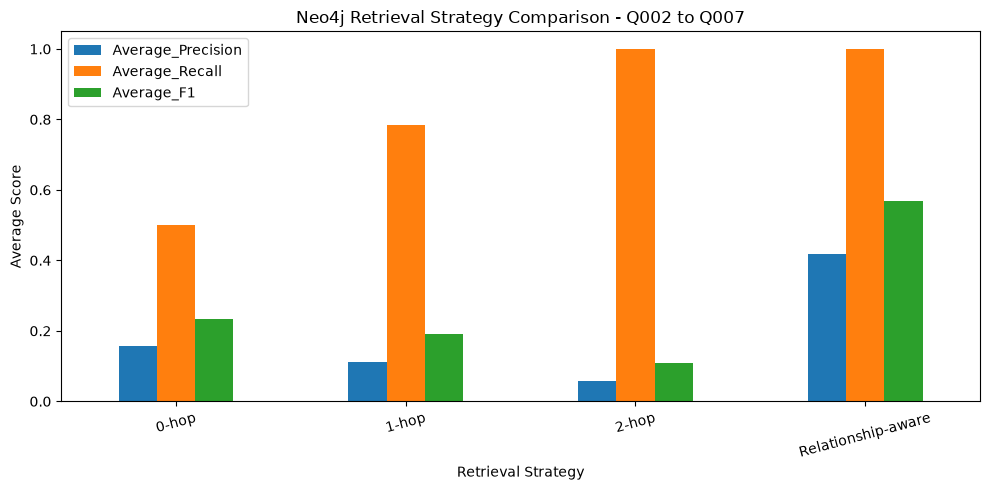

In [20]:
import matplotlib.pyplot as plt

ax = summary_df.set_index("Method")[
    ["Average_Precision", "Average_Recall", "Average_F1"]
].plot(kind="bar", figsize=(10, 5))

ax.set_title("Neo4j Retrieval Strategy Comparison - Q002 to Q007")
ax.set_xlabel("Retrieval Strategy")
ax.set_ylabel("Average Score")
ax.set_ylim(0, 1.05)

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [21]:
output_dir = project_root / "results"
output_dir.mkdir(exist_ok=True)

multi_eval_df.to_csv(
    output_dir / "retrieval_evaluation_q002_q007.csv",
    index=False,
    encoding="utf-8-sig"
)

summary_df.to_csv(
    output_dir / "retrieval_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Evaluation results saved!")

Evaluation results saved!
